In [1]:
import gymnasium as gym
from gymnasium import spaces
import numpy as np
import pandas as pd
import torch


device = torch.device("cuda") if torch.cuda.is_available() else torch.device("cpu")


class CRNetwork(gym.Env):
    metadata = {"render_modes": []}

    def __init__(
        self, n_ST=2, noise=1e-6, int_thresh=-28.0,
        max_power=10e-3, steps_per_run=100, dtype=np.float32, seed=None,
        interference_reference_w=1.0, error_variance=0.1, hist_len = 1,
        reward_mode="paper", alpha=0.2,beta=10.0):
        super().__init__()

        if not isinstance(n_ST, (int, np.integer)) or n_ST < 1:
            raise ValueError("n_ST must be a positive integer.")
        if not isinstance(steps_per_run, (int, np.integer)) or steps_per_run < 1:
            raise ValueError("steps_per_run must be a positive integer.")
        if not np.issubdtype(np.dtype(dtype), np.floating):
            raise ValueError("Use a floating-point observation dtype.")

        parameters = (noise, int_thresh, max_power, interference_reference_w)
        if not np.all(np.isfinite(parameters)):
            raise ValueError("Environment parameters must be finite.")
        if noise <= 0 or max_power <= 0 or interference_reference_w <= 0:
            raise ValueError("Noise, power budget, and interference reference must be positive.")
        if not np.isfinite(error_variance) or error_variance < 0:
            raise ValueError("error_variance must be finite and nonnegative.")
        if not np.isfinite(alpha) or not 0 <= alpha <= 1:
            raise ValueError("alpha must be between 0 and 1.")
        if not np.isfinite(beta) or beta < 0:
            raise ValueError("beta must be finite and nonnegative.")

        self.k = int(n_ST)
        self.N0 = float(noise)
        self.Pmax = float(max_power)
        self.Ith = float(10**(int_thresh / 10))

        if not np.isfinite(self.Ith) or self.Ith <= 0:
            raise ValueError("Converted interference threshold must be finite and positive.")

        self.max_steps = int(steps_per_run)
        self.dtype = np.dtype(dtype)

        self.hist_len = int(hist_len)
        assert self.hist_len >= 1
        self.obs_dim = (self.hist_len + 1) * self.k + 1
        self.action_dim = self.k

        self.error_variance = float(error_variance)
        self.beta = float(beta)
        self.alpha = float(alpha)

        self.reward_mode = "paper" if reward_mode == "paper" else "custom"

        self.observation_space = spaces.Box(
            low=-np.inf,
            high=np.inf,
            shape=(self.obs_dim,),
            dtype=self.dtype
        )
        self.action_space = spaces.Box(
            low=-1.0,
            high=1.0,
            shape=(self.k,),
            dtype=self.dtype
        )

        # Random number generator
        self.np_random = np.random.default_rng(seed)
        self.step_count = 0
        self._needs_reset = True

    def get_channel_gain(self, update=True):

        # Update complex channel coefficients only when requested
        if update:
           # Noisy estimate
            w_p = (self.np_random.standard_normal(self.k) + 1j * self.np_random.standard_normal(self.k)) / np.sqrt(2)
            w_s = (self.np_random.standard_normal(self.k)+ 1j * self.np_random.standard_normal(self.k)) / np.sqrt(2)

            # Temporally correlated ST-PR channels
            self.hint = ((1 - self.alpha) * self.hint + np.sqrt(2 * self.alpha - self.alpha**2) * w_p)
            self.hsr = ((1 - self.alpha) * self.hsr + np.sqrt(2 * self.alpha - self.alpha**2) * w_s)
        # Actual channel power gains
        g_pr_actual = np.abs(self.hint)**2
        g_sr = np.abs(self.hsr)**2
        # Imperfect CSI on ST-PR links only
        error = np.sqrt(self.error_variance / 2) * (self.np_random.standard_normal(self.k) + 1j * self.np_random.standard_normal(self.k))

        hpr_est = self.hint + error
        gpr_est = np.abs(hpr_est)**2
        self.hpr_est = hpr_est

        return g_pr_actual, gpr_est, g_sr

    def _observation(self):
        # return np.concatenate(
        #     [self.hint_est, self.P_prev, [self.r_prev]]
        # ).astype(self.dtype)
        return np.concatenate([self.est_hist.ravel(), self.P_prev, [self.r_prev]]).astype(self.dtype)

    def reset(self, *, seed=None, options=None):

        super().reset(seed=seed)

        self.step_count = 0
        self.P_prev = np.zeros(self.k)
        self.r_prev = 0.0

        # Initialize complex channel coefficients
        self.hint = (self.np_random.standard_normal(self.k) + 1j * self.np_random.standard_normal(self.k)) / np.sqrt(2)

        self.hsr = (self.np_random.standard_normal(self.k) + 1j * self.np_random.standard_normal(self.k)) / np.sqrt(2)

        # Initial channel gains and imperfect CSI
        self.g_pr_actual, self.hint_est, self.g_sr = (self.get_channel_gain(update=False))
        self.est_hist = np.tile(self.hint_est, (self.hist_len, 1))   # pad history with the current estimate

        self._needs_reset = False

        return self._observation(), {}

    def step(self, action):

        if self._needs_reset:
            raise RuntimeError("Call reset() before stepping or after an episode ends.")

        action = np.asarray(action, dtype=np.float64)

        if action.shape != (self.k,) or not np.all(np.isfinite(action)):
            raise ValueError(f"Expected a finite action with shape ({self.k},).")

        raw_action = np.clip(action, -1.0, 1.0)

        # Action-to-power mapping
        fractions = (raw_action + 1.0) / 2.0
        powers = fractions * self.Pmax

        # Capacity using actual desired channel gains
        signal_power = powers * self.g_sr
        snr = signal_power / self.N0
        capacity = np.log2(1.0 + snr)

        # Actual primary interference
        interference = float(np.sum(powers * self.g_pr_actual))

        normalized_violation = max(
            0.0,
            (interference - self.Ith) / self.Ith
        )

        power_ok = bool(
            np.all(powers >= 0) and np.all(powers <= self.Pmax)
        )

        feasible = bool(interference <= self.Ith and power_ok)

        # Reward calculation
        if self.reward_mode == "paper":
            reward = float(capacity.sum()) if feasible else -interference
        else:
            reward = float(capacity.sum()) - self.beta * normalized_violation

        info = {
            "capacity": capacity.copy(),
            "snr": snr.copy(),
            "interference": interference,
            "constraints_satisfied": feasible,
            "allocation_fractions": fractions.copy(),
            "transmit_powers": powers.copy(),
            "actual_interference_gains": self.g_pr_actual.copy(),
            "desired_gains": self.g_sr.copy(),
            "estimated_interference": float(np.sum(powers * self.hint_est)),
            "normalized_excess": float(normalized_violation),
            "penalty": float(self.beta * normalized_violation),
            "actual_violation": bool(interference > self.Ith),
            "estimated_violation": bool(np.sum(powers * self.hint_est) > self.Ith),
        }
        # Store previous action and reward
        self.P_prev = powers.copy()
        self.r_prev = reward

        self.step_count += 1

        terminated = False
        truncated = bool(self.step_count >= self.max_steps)

        # Generate next channel realization for the next observation
        self.g_pr_actual, self.hint_est, self.g_sr = (self.get_channel_gain(update=True))
        self.est_hist = np.vstack([self.hint_est, self.est_hist[:-1]])  # newest first

        self._needs_reset = truncated

        return self._observation(), reward, terminated, truncated, info


In [2]:
class ReplayBuffer:
  def __init__(self, state_dim, action_dim, max_size):
    self.mem_size = max_size
    self.mem_cntr = 0
    self.state_memory = np.zeros((self.mem_size, state_dim), dtype = np.float32)
    self.next_state_memory = np.zeros((self.mem_size, state_dim), dtype = np.float32)
    self.action_memory = np.zeros((self.mem_size, action_dim), dtype = np.float32)
    self.reward_memory = np.zeros(self.mem_size, dtype = np.float32)

    self.terminal_memory = np.zeros(self.mem_size, dtype = np.uint8)

  def store_transition(self, state, action, reward, next_state, done):
    index = self.mem_cntr % self.mem_size
    self.state_memory[index] = state
    self.action_memory[index] = action
    self.reward_memory[index] = reward

    self.next_state_memory[index] = next_state
    self.terminal_memory[index] = done

    self.mem_cntr += 1

  def sample_batch(self, batch_size = 256):
    max_mem = min(self.mem_cntr, self.mem_size)
    batch = np.random.choice(max_mem, batch_size)
    states = self.state_memory[batch]
    actions = self.action_memory[batch]
    rewards = self.reward_memory[batch]
    states_ = self.next_state_memory[batch]
    dones = self.terminal_memory[batch]
    return states, actions, rewards, states_, dones

## Networks

In [3]:
import torch
import torch.nn as nn
import torch.nn.functional as F
torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class Actor(nn.Module):
  def __init__(self, state_dim, action_dim, action_max):
    super(Actor, self).__init__()
    self.action_max = action_max
    self.device = device

    self.linear1 = nn.Linear(state_dim, 64)
    self.linear2 = nn.Linear(64, 64)
    self.linear3 = nn.Linear(64, action_dim)

  def forward(self, state):
    x = F.relu(self.linear1(state))
    x = F.relu(self.linear2(x))
    x = torch.tanh(self.linear3(x))

    action_max = torch.as_tensor(
        self.action_max,
        dtype=x.dtype,
        device=x.device,
    )

    return x * action_max

class Critic(nn.Module):
  def __init__(self, state_dim, action_dim, trainable = True):
    super(Critic, self).__init__()
    self.device = device
    self.W_s = nn.Parameter(torch.randn(state_dim, 64), requires_grad = trainable)
    self.W_a = nn.Parameter(torch.randn(action_dim, 64), requires_grad = trainable)
    self.b1 = nn.Parameter(torch.randn(1, 64), requires_grad = trainable)
    self.linear1 = nn.Linear(64, 64)
    self.linear2 = nn.Linear(64, 1)

  def forward(self, state, action):
    x = F.relu(torch.matmul(state, self.W_s) + torch.matmul(action, self.W_a) + self.b1)
    x = F.relu(self.linear1(x))
    x = self.linear2(x)
    return x

In [4]:

from copy import deepcopy
from pathlib import Path

import numpy as np
import torch
import torch.nn.functional as F


class DDPG_Agent:
    def __init__(self, alpha, beta, state_dim, tau, action_max, action_min,
                 gamma=0.99, action_dim=2, max_size=1_000_000,
                 batch_size=256, seed=0, device=None):
        self.device = torch.device(
            device if device is not None
            else ("cuda" if torch.cuda.is_available() else "cpu")
        )
        self.state_dim = state_dim
        self.action_dim = action_dim
        self.gamma = gamma
        self.tau = tau
        self.batch_size = batch_size
        self.alpha = alpha
        self.beta = beta


        self.low = np.broadcast_to(
            np.asarray(action_min, dtype=np.float32), (action_dim,)
        ).copy()
        self.high = np.broadcast_to(
            np.asarray(action_max, dtype=np.float32), (action_dim,)
        ).copy()
        if (not np.all(np.isfinite([self.low, self.high]))
                or np.any(self.high <= self.low)):
            raise ValueError("Action bounds must be finite, with high > low.")
        if not np.allclose(self.low, -self.high):
            raise ValueError("Your tanh actor requires symmetric bounds, e.g. [-1, 1].")
        if batch_size < 1 or max_size < batch_size:
            raise ValueError("Require max_size >= batch_size >= 1.")
        if not 0 <= gamma <= 1 or not 0 < tau <= 1:
            raise ValueError("Require gamma in [0, 1] and tau in (0, 1].")

        torch.manual_seed(seed)

        np.random.seed(seed)
        self.rng = np.random.default_rng(seed)
        self.memory = ReplayBuffer(state_dim, action_dim, max_size)
        if not np.issubdtype(self.memory.action_memory.dtype, np.floating):
            raise TypeError("Change ReplayBuffer.action_memory dtype to np.float32 first.")

        self.actor = Actor(state_dim, action_dim, self.high.copy()).to(self.device)
        self.critic = Critic(state_dim, action_dim).to(self.device)

        self.target_actor = deepcopy(self.actor).requires_grad_(False)
        self.target_critic = deepcopy(self.critic).requires_grad_(False)
        for network in (self.actor, self.critic, self.target_actor, self.target_critic):
            network.device = self.device
        self.target_actor.eval()
        self.target_critic.eval()

        self.actor.optimizer = torch.optim.Adam(self.actor.parameters(), lr=alpha)
        self.critic.optimizer = torch.optim.Adam(self.critic.parameters(), lr=beta)

    def choose_action(self, s, noise_std=0.0):
        if noise_std < 0:
            raise ValueError("noise_std must be nonnegative.")
        s = np.asarray(s, dtype=np.float32)
        if s.shape != (self.state_dim,) or not np.all(np.isfinite(s)):
            raise ValueError(f"Expected a finite observation of shape ({self.state_dim},).")
        state = torch.as_tensor(s, device=self.device).unsqueeze(0)
        was_training = self.actor.training
        self.actor.eval()
        with torch.no_grad():
            action = self.actor(state).cpu().numpy().flatten()
        self.actor.train(was_training)

        if noise_std > 0:
            noise = self.rng.normal(size=self.action_dim)
            action = action + noise_std * (self.high - self.low) / 2 * noise
        return np.clip(action, self.low, self.high).astype(np.float32)

    def remember(self, state, action, reward, state_, done):
        # done must mean true termination; pass terminated, not truncated.
        self.memory.store_transition(state, action, float(reward), state_, done)

    def learn(self):
        if self.memory.mem_cntr < self.batch_size:
            return None
        states, actions, rewards, next_states, done = self.memory.sample_batch(self.batch_size)
        states = torch.as_tensor(states, dtype=torch.float32, device=self.device)
        next_states = torch.as_tensor(next_states, dtype=torch.float32, device=self.device)
        actions = torch.as_tensor(actions, dtype=torch.float32, device=self.device)
        rewards = torch.as_tensor(rewards, dtype=torch.float32, device=self.device).reshape(-1, 1)
        done = torch.as_tensor(done, dtype=torch.float32, device=self.device).reshape(-1, 1)

        self.actor.train()
        self.critic.train()

        with torch.no_grad():
            next_actions = self.target_actor(next_states)
            next_q = self.target_critic(next_states, next_actions)
            target_q = rewards + self.gamma * (1 - done) * next_q


        current_q = self.critic(states, actions)
        critic_loss = F.mse_loss(current_q, target_q)
        self.critic.optimizer.zero_grad()
        critic_loss.backward()
        self.critic.optimizer.step()


        self.critic.requires_grad_(False)
        actor_loss = -self.critic(states, self.actor(states)).mean()
        self.actor.optimizer.zero_grad()
        actor_loss.backward()
        self.actor.optimizer.step()
        self.critic.requires_grad_(True)


        self.update_network_parameters()
        return actor_loss.item(), critic_loss.item()

    @torch.no_grad()
    def update_network_parameters(self, tau=None):
        tau = self.tau if tau is None else tau
        if not 0 <= tau <= 1:
            raise ValueError("tau must lie in [0, 1].")
        for source, target in ((self.actor, self.target_actor),
                               (self.critic, self.target_critic)):
            for parameter, target_parameter in zip(source.parameters(), target.parameters()):
                target_parameter.mul_(1 - tau).add_(parameter, alpha=tau)

    def save_models(self, path="ddpg_models.pt"):
        """Save network weights for evaluation; not a full resume checkpoint."""
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        torch.save({
            "actor": self.actor.state_dict(),
            "critic": self.critic.state_dict(),
            "target_actor": self.target_actor.state_dict(),
            "target_critic": self.target_critic.state_dict(),
            "state_dim": self.state_dim,
            "low": self.low.tolist(), "high": self.high.tolist(),
        }, path)

    def load_models(self, path="ddpg_models.pt"):
        """Load weights into an agent with matching networks, dimensions/bounds."""
        data = torch.load(path, map_location=self.device, weights_only=True)
        if (data["state_dim"] != self.state_dim
                or np.asarray(data["low"]).shape != self.low.shape
                or np.asarray(data["high"]).shape != self.high.shape
                or not np.allclose(data["low"], self.low)
                or not np.allclose(data["high"], self.high)):
            raise ValueError("Checkpoint observation size or action bounds do not match.")
        self.actor.load_state_dict(data["actor"])
        self.critic.load_state_dict(data["critic"])
        self.target_actor.load_state_dict(data["target_actor"])
        self.target_critic.load_state_dict(data["target_critic"])
        self.actor.eval()
        self.critic.eval()


In [5]:
from google.colab import files
files.upload();

Saving utils.py to utils (1).py



========== DDPG ENVIRONMENT CONFIGURATION ==========
Secondary pairs       : 2
State dimension       : 5
Action dimension      : 2
Maximum power         : 10.00 mW per SU
Noise power           : 1.000000e-06 W
Interference threshold: 2.00 dBm
Training steps        : 100000
CSI error variance    : 0.1
Discount factor       : 0.9
Target update tau     : 0.005
Actor learning rate   : 0.001
Critic learning rate  : 0.002
Replay buffer size    : 1000000
Batch size            : 256
Warm-up steps         : 1000
Initial noise std     : 0.2
Final noise std       : 0.05

Training device: cpu
Episode    1/1000 | Steps    100 | Reward -38.4346 | Capacity  22.3830 | Interference   10.490 dBm | Violations  94.00% | Recent reward -38.4346 | Recent capacity  22.3830
Episode   11/1000 | Steps   1100 | Reward  -7.3178 | Capacity  13.9158 | Interference    6.487 dBm | Violations  55.00% | Recent reward -27.3180 | Recent capacity  21.0531
Episode   21/1000 | Steps   2100 | Reward   5.7911 | Capacity   7.8

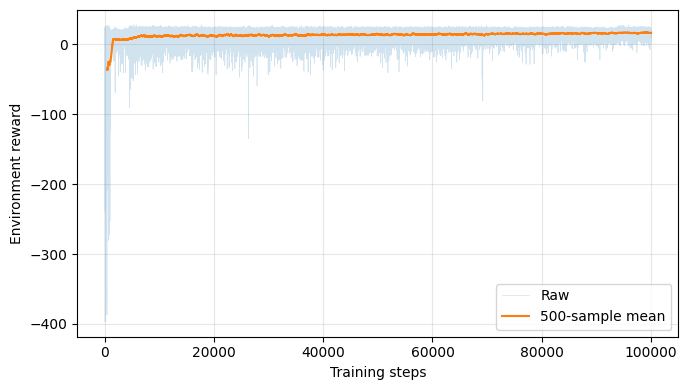

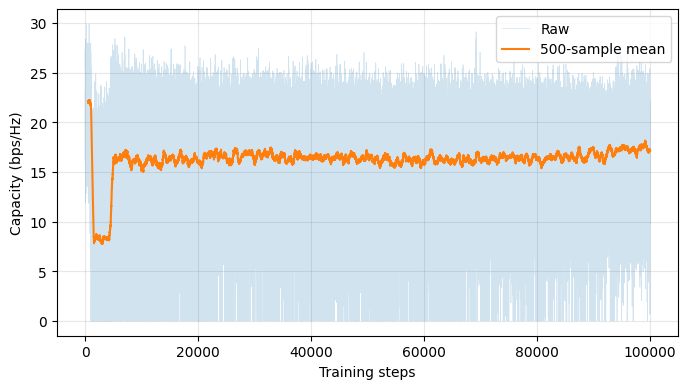

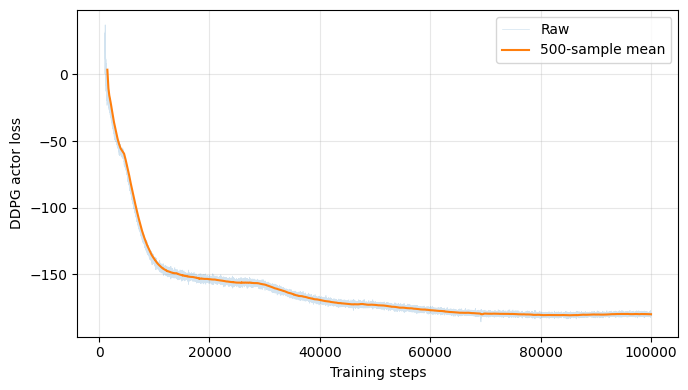

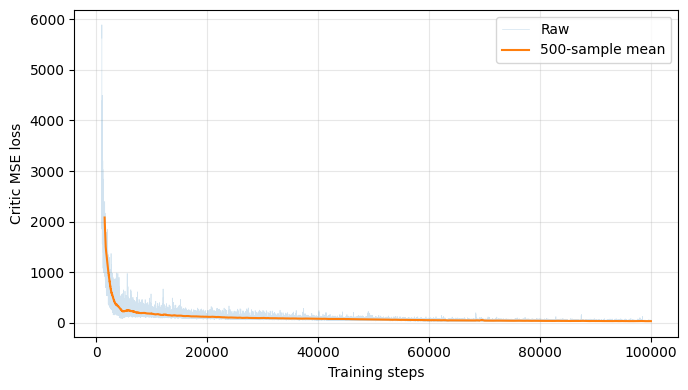

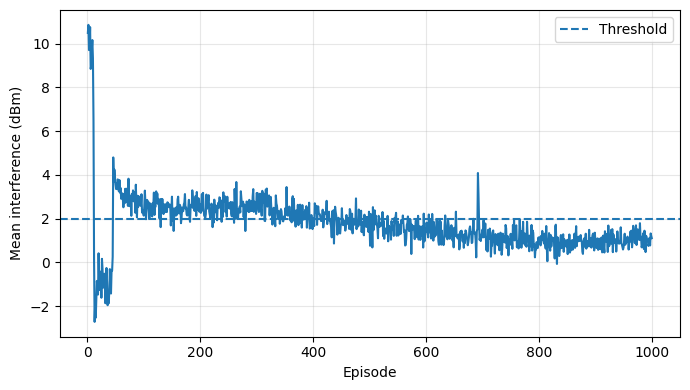

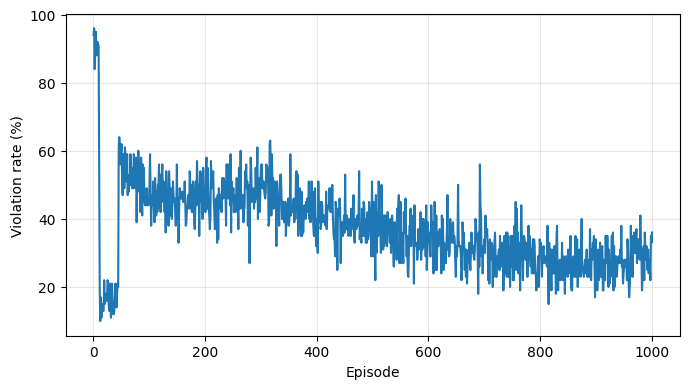

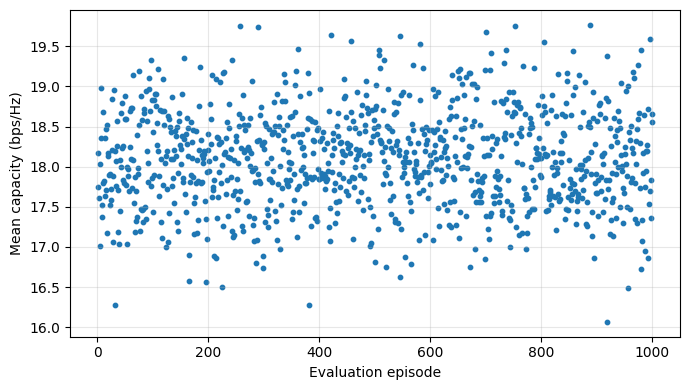

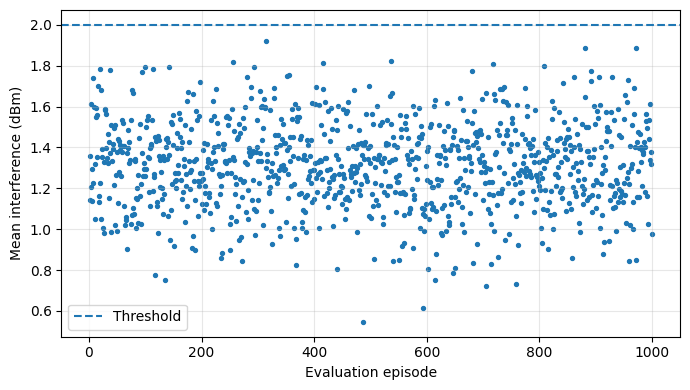

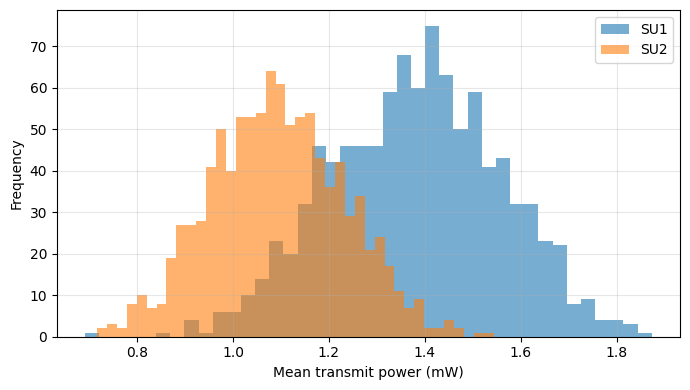

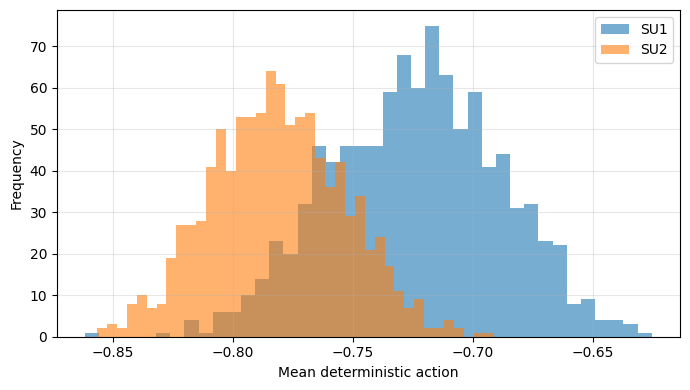


                 DDPG RESULTS

Training steps: 100000
Training time: 477.22 seconds

TRAINING
Mean reward: 13.1287
Mean capacity: 16.2229 bps/Hz
Mean interference: 2.0200 dBm
Violation rate: 37.51%
Mean total power: 2.6193 mW

DDPG CONFIGURATION
Gamma: 0.9
Tau: 0.005
Actor learning rate: 0.001
Critic learning rate: 0.002
Replay buffer size: 1000000
Batch size: 256
Warm-up steps: 1000
Initial exploration noise: 0.2
Final exploration noise: 0.05

EVALUATION
Mean reward: 17.3555
Mean capacity: 18.1004 +/- 0.5995 bps/Hz
Mean interference: 1.3196 dBm
Threshold: 2.00 dBm
Violation rate: 29.52%
Constraint satisfaction: 70.48%
SU1 mean power: 1.3798 mW
SU1 mean action: -0.7240
SU2 mean power: 1.0934 mW
SU2 mean action: -0.7813
Execution time: 0.2074 ms/action

Saved results to:
/content/ddpg_5d


In [6]:

from pathlib import Path
import time
import numpy as np
import torch
import matplotlib.pyplot as plt
from utils import *


# ============================================================
# 1. ENVIRONMENT AND EXPERIMENT CONFIGURATION
# ============================================================

N_ST = 2

MAX_POWER_MW = 10.0
NOISE_POWER_MW = 1e-3
ITH_DBM = 2.0

MAX_POWER = MAX_POWER_MW * 1e-3
N0 = NOISE_POWER_MW * 1e-3
ITH_DBW = ITH_DBM - 30.0

STEPS_PER_RUN = 100

NUM_EPISODES = 1000
TOTAL_TRAINING_STEPS = NUM_EPISODES * STEPS_PER_RUN

ACTOR_LR = 1e-3
CRITIC_LR = 2e-3

GAMMA = 0.9
TAU = 0.005

MAX_SIZE = 1_000_000
BATCH_SIZE = 256

WARMUP_STEPS = 1000

NOISE_STD_START = 0.20
NOISE_STD_END = 0.05

EVAL_EPISODES = 1000
EVAL_SEED_OFFSET = 100_000

SMOOTH_WINDOW = 500

seed = 0

OUTPUT_DIR = Path("ddpg_5d")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. RANDOM SEEDS
# ============================================================

torch.manual_seed(seed)
np.random.seed(seed)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)


# ============================================================
# 3. ENVIRONMENT
# ============================================================

env = CRNetwork(
    n_ST=N_ST,
    noise=N0,
    int_thresh=ITH_DBW,
    max_power=MAX_POWER,
    steps_per_run=STEPS_PER_RUN,
    dtype=np.float32,
    seed=seed,
    alpha=0.2,
    reward_mode = "custom"
)


# ============================================================
# 4. CONFIGURATION VALIDATION
# ============================================================

expected_ith_w = dbm_to_watts(ITH_DBM)

assert np.isclose(env.Ith, expected_ith_w, rtol=1e-6)
assert np.isclose(env.N0, N0)
assert np.isclose(env.Pmax, MAX_POWER)

STATE_DIM = env.observation_space.shape[0]
ACTION_DIM = env.action_space.shape[0]

assert STATE_DIM == 5, f"Expected 5 states, got {STATE_DIM}"
assert ACTION_DIM == 2, f"Expected 2 actions, got {ACTION_DIM}"

assert MAX_SIZE >= BATCH_SIZE
assert STEPS_PER_RUN > 0
assert WARMUP_STEPS >= 0

print("\n========== DDPG ENVIRONMENT CONFIGURATION ==========")
print(f"Secondary pairs       : {N_ST}")
print(f"State dimension       : {STATE_DIM}")
print(f"Action dimension      : {ACTION_DIM}")
print(f"Maximum power         : {MAX_POWER_MW:.2f} mW per SU")
print(f"Noise power           : {N0:.6e} W")
print(f"Interference threshold: {ITH_DBM:.2f} dBm")
print(f"Training steps        : {TOTAL_TRAINING_STEPS}")
print(f"CSI error variance    : {env.error_variance}")
print(f"Discount factor       : {GAMMA}")
print(f"Target update tau     : {TAU}")
print(f"Actor learning rate   : {ACTOR_LR}")
print(f"Critic learning rate  : {CRITIC_LR}")
print(f"Replay buffer size    : {MAX_SIZE}")
print(f"Batch size            : {BATCH_SIZE}")
print(f"Warm-up steps         : {WARMUP_STEPS}")
print(f"Initial noise std     : {NOISE_STD_START}")
print(f"Final noise std       : {NOISE_STD_END}")
print("=====================================================\n")


# ============================================================
# 5. INITIALIZE DDPG
# ============================================================

ddpg_agent = DDPG_Agent(
    alpha=ACTOR_LR,
    beta=CRITIC_LR,
    state_dim=STATE_DIM,
    tau=TAU,
    action_max=env.action_space.high,
    action_min=env.action_space.low,
    gamma=GAMMA,
    action_dim=ACTION_DIM,
    max_size=MAX_SIZE,
    batch_size=BATCH_SIZE,
    seed=seed
)

training_device = next(
    ddpg_agent.actor.parameters()
).device

print("Training device:", training_device)


# ============================================================
# 6. HISTORY ARRAYS
# ============================================================

step_numbers = []
step_rewards = []
step_capacities = []

step_powers = []
step_total_power = []

step_violations = []
step_actions = []

step_interference_w = []

episode_interference_w = []
episode_interference_dbm = []
episode_violation_rate = []
episode_reward = []
episode_capacity = []

actor_losses = []
critic_losses = []
loss_steps = []

total_time = 0


# ============================================================
# 7. TRAINING LOOP
# ============================================================

if training_device.type == "cuda":
    torch.cuda.synchronize(training_device)

start_time = time.perf_counter()

for episode in range(NUM_EPISODES):

    obs, _ = env.reset(seed=seed + episode)

    obs = prep_obs(
        obs,
        env.Pmax,
        N_ST
    ).astype(np.float32)

    ep_interference_sum = 0.0
    ep_violations = 0
    ep_reward_sum = 0.0
    ep_capacity_sum = 0.0

    for j in range(STEPS_PER_RUN):

        # --------------------------------------------
        # SELECT ACTION
        # --------------------------------------------

        progress = min(
            total_time / TOTAL_TRAINING_STEPS,
            1.0
        )

        noise_std = (
            NOISE_STD_START
            + progress * (NOISE_STD_END - NOISE_STD_START)
        )

        # Random warm-up exploration
        if total_time < WARMUP_STEPS:

            action = ddpg_agent.rng.uniform(
                -1.0,
                1.0,
                size=ACTION_DIM
            ).astype(np.float32)

        else:

            action = ddpg_agent.choose_action(
                obs,
                noise_std=noise_std
            )

        action = np.asarray(action, dtype=np.float32)

        # --------------------------------------------
        # ENVIRONMENT STEP
        # --------------------------------------------

        next_obs, reward, terminated, truncated, info = env.step(
            action.copy()
        )

        next_obs = prep_obs(
            next_obs,
            env.Pmax,
            N_ST
        ).astype(np.float32)

        reward = float(reward)

        capacity = np.asarray(
            info["capacity"],
            dtype=np.float64
        )

        powers_w = step_powers_w(
            info,
            action,
            env
        )

        interference_w = float(info["interference"])

        violated = bool(interference_w > env.Ith)

        # --------------------------------------------
        # RECORD STEP STATISTICS
        # --------------------------------------------

        total_time += 1

        step_numbers.append(total_time)
        step_rewards.append(reward)
        step_capacities.append(float(capacity.sum()))

        step_powers.append(powers_w.copy())
        step_total_power.append(float(powers_w.sum()))

        step_violations.append(int(violated))
        step_actions.append(action.copy())

        step_interference_w.append(interference_w)

        # --------------------------------------------
        # EPISODE STATISTICS
        # --------------------------------------------

        ep_interference_sum += interference_w
        ep_violations += int(violated)
        ep_reward_sum += reward
        ep_capacity_sum += float(capacity.sum())

        # --------------------------------------------
        # STORE TRANSITION
        # --------------------------------------------

        # Only true termination is terminal.
        # Truncation should still bootstrap in DDPG.

        ddpg_agent.remember(
            obs,
            action,
            reward,
            next_obs,
            terminated
        )

        obs = next_obs

        # --------------------------------------------
        # DDPG UPDATE
        # --------------------------------------------

        if total_time >= WARMUP_STEPS:

            losses = ddpg_agent.learn()

            if losses is not None:

                actor_losses.append(float(losses[0]))
                critic_losses.append(float(losses[1]))

                loss_steps.append(total_time)

        if terminated or truncated:
            break

    # --------------------------------------------
    # EPISODE SUMMARIES
    # --------------------------------------------

    steps_done = j + 1

    mean_interference = ep_interference_sum / steps_done

    episode_interference_w.append(mean_interference)

    episode_interference_dbm.append(
        float(watts_to_dbm(mean_interference))
    )

    episode_violation_rate.append(
        ep_violations / steps_done
    )

    episode_reward.append(
        ep_reward_sum / steps_done
    )

    episode_capacity.append(
        ep_capacity_sum / steps_done
    )

    # --------------------------------------------
    # PROGRESS DISPLAY EVERY 10 EPISODES
    # --------------------------------------------

    if episode % 10 == 0 or episode == NUM_EPISODES - 1:

        recent = min(10, len(episode_reward))

        print(
            f"Episode {episode + 1:4d}/{NUM_EPISODES} | "
            f"Steps {total_time:6d} | "
            f"Reward {episode_reward[-1]:8.4f} | "
            f"Capacity {episode_capacity[-1]:8.4f} | "
            f"Interference {episode_interference_dbm[-1]:8.3f} dBm | "
            f"Violations {100 * episode_violation_rate[-1]:6.2f}% | "
            f"Recent reward {np.mean(episode_reward[-recent:]):8.4f} | "
            f"Recent capacity {np.mean(episode_capacity[-recent:]):8.4f}"
        )


if training_device.type == "cuda":
    torch.cuda.synchronize(training_device)

training_seconds = time.perf_counter() - start_time


# ============================================================
# 8. DETERMINISTIC EVALUATION
# ============================================================

eval_capacity = []
eval_interference_w = []
eval_violation = []
eval_reward = []

eval_powers = []
eval_actions = []

action_seconds = 0.0
action_calls = 0

ddpg_agent.actor.eval()
ddpg_agent.critic.eval()

for e in range(EVAL_EPISODES):

    obs, _ = env.reset(
        seed=EVAL_SEED_OFFSET + e
    )

    obs = prep_obs(
        obs,
        env.Pmax,
        N_ST
    ).astype(np.float32)

    ep_capacity = 0.0
    ep_interference = 0.0
    ep_violations = 0
    ep_reward = 0.0

    ep_powers = []
    ep_actions = []

    for j in range(STEPS_PER_RUN):

        t0 = time.perf_counter()

        action = ddpg_agent.choose_action(
            obs,
            noise_std=0.0
        )

        action_seconds += time.perf_counter() - t0
        action_calls += 1

        action = np.asarray(action, dtype=np.float32)

        next_obs, reward, terminated, truncated, info = env.step(
            action.copy()
        )

        next_obs = prep_obs(
            next_obs,
            env.Pmax,
            N_ST
        ).astype(np.float32)

        ep_capacity += float(
            np.sum(info["capacity"])
        )

        ep_interference += float(
            info["interference"]
        )

        ep_violations += int(
            float(info["interference"]) > env.Ith
        )

        ep_reward += float(reward)

        ep_powers.append(
            step_powers_w(info, action, env)
        )

        ep_actions.append(action.copy())

        obs = next_obs

        if terminated or truncated:
            break

    n = j + 1

    eval_capacity.append(ep_capacity / n)
    eval_interference_w.append(ep_interference / n)
    eval_violation.append(ep_violations / n)
    eval_reward.append(ep_reward / n)

    eval_powers.append(
        np.mean(ep_powers, axis=0)
    )

    eval_actions.append(
        np.mean(ep_actions, axis=0)
    )

ms_per_action = (
    1000.0 * action_seconds / max(action_calls, 1)
)

eval_capacity = np.asarray(eval_capacity)
eval_interference_w = np.asarray(eval_interference_w)
eval_violation = np.asarray(eval_violation)
eval_reward = np.asarray(eval_reward)

eval_powers = np.asarray(eval_powers)
eval_actions = np.asarray(eval_actions)

eval_interference_dbm = watts_to_dbm(eval_interference_w)


# ============================================================
# 9. SAVE MODEL AND TRAINING HISTORY
# ============================================================

np.savez_compressed(
    OUTPUT_DIR / "ddpg_training_history.npz",

    steps=step_numbers,
    rewards=step_rewards,
    capacity=step_capacities,

    powers_w=step_powers,
    total_power_w=step_total_power,

    violations=step_violations,
    actions=step_actions,
    interference_w=step_interference_w,

    episode_interference_w=episode_interference_w,
    episode_interference_dbm=episode_interference_dbm,
    episode_violation_rate=episode_violation_rate,
    episode_reward=episode_reward,
    episode_capacity=episode_capacity,

    loss_steps=loss_steps,
    actor_loss=actor_losses,
    critic_loss=critic_losses,

    eval_capacity=eval_capacity,
    eval_interference_w=eval_interference_w,
    eval_interference_dbm=eval_interference_dbm,
    eval_violation_rate=eval_violation,
    eval_reward=eval_reward,
    eval_powers=eval_powers,
    eval_actions=eval_actions,

    ms_per_action=ms_per_action,

    pmax_w=env.Pmax,
    noise_w=env.N0,
    threshold_w=env.Ith,
    threshold_dbm=ITH_DBM,
    threshold_dbw=ITH_DBW,

    gamma=GAMMA,
    actor_lr=ACTOR_LR,
    critic_lr=CRITIC_LR,
    tau=TAU,
    batch_size=BATCH_SIZE,
    warmup_steps=WARMUP_STEPS,
    noise_std_start=NOISE_STD_START,
    noise_std_end=NOISE_STD_END,

    seed=seed,
    training_seconds=training_seconds
)

ddpg_agent.save_models(
    OUTPUT_DIR / "ddpg_weights.pt"
)


# ============================================================
# 10. PLOTTING HELPERS
# ============================================================

def save_fig(fig, name):

    fig.tight_layout()

    fig.savefig(
        OUTPUT_DIR / f"{name}.png",
        dpi=300
    )

    fig.savefig(
        OUTPUT_DIR / f"{name}.pdf"
    )

    plt.show()
    plt.close(fig)


def plot_curve(x, values, ylabel, filename):

    x = np.asarray(x)
    values = np.asarray(values, dtype=np.float64)

    if len(values) == 0:
        print(f"Skipping {filename}: no data.")
        return

    window = min(SMOOTH_WINDOW, len(values))

    cumulative = np.concatenate(
        ([0.0], np.cumsum(values))
    )

    smoothed = (
        cumulative[window:] - cumulative[:-window]
    ) / window

    fig, ax = plt.subplots(figsize=(7, 4))

    ax.plot(
        x,
        values,
        alpha=0.2,
        linewidth=0.5,
        label="Raw"
    )

    ax.plot(
        x[window - 1:],
        smoothed,
        linewidth=1.5,
        label=f"{window}-sample mean"
    )

    ax.set_xlabel("Training steps")
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    ax.legend()

    save_fig(fig, filename)


# ============================================================
# 11. TRAINING PLOTS
# ============================================================

plot_curve(
    step_numbers,
    step_rewards,
    "Environment reward",
    "reward"
)

plot_curve(
    step_numbers,
    step_capacities,
    "Capacity (bps/Hz)",
    "capacity"
)

plot_curve(
    loss_steps,
    actor_losses,
    "DDPG actor loss",
    "actor_loss"
)

plot_curve(
    loss_steps,
    critic_losses,
    "Critic MSE loss",
    "critic_loss"
)


# ============================================================
# 12. INTERFERENCE AND VIOLATION PLOTS
# ============================================================

episodes_axis = np.arange(
    1,
    len(episode_interference_dbm) + 1
)

fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    episodes_axis,
    episode_interference_dbm
)

ax.axhline(
    ITH_DBM,
    linestyle="--",
    label="Threshold"
)

ax.set_xlabel("Episode")
ax.set_ylabel("Mean interference (dBm)")
ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "training_interference")


fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(
    episodes_axis,
    100 * np.asarray(episode_violation_rate)
)

ax.set_xlabel("Episode")
ax.set_ylabel("Violation rate (%)")
ax.grid(alpha=0.3)

save_fig(fig, "training_violations")


# ============================================================
# 13. EVALUATION PLOTS
# ============================================================

eval_runs = np.arange(
    1,
    EVAL_EPISODES + 1
)

fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(
    eval_runs,
    eval_capacity,
    s=10
)

ax.set_xlabel("Evaluation episode")
ax.set_ylabel("Mean capacity (bps/Hz)")
ax.grid(alpha=0.3)

save_fig(fig, "evaluation_capacity")


fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(
    eval_runs,
    eval_interference_dbm,
    s=8
)

ax.axhline(
    ITH_DBM,
    linestyle="--",
    label="Threshold"
)

ax.set_xlabel("Evaluation episode")
ax.set_ylabel("Mean interference (dBm)")
ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "evaluation_interference")


fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(
    eval_powers[:, 0] * 1000,
    bins=40,
    alpha=0.6,
    label="SU1"
)

ax.hist(
    eval_powers[:, 1] * 1000,
    bins=40,
    alpha=0.6,
    label="SU2"
)

ax.set_xlabel("Mean transmit power (mW)")
ax.set_ylabel("Frequency")
ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "evaluation_power")


fig, ax = plt.subplots(figsize=(7, 4))

ax.hist(
    eval_actions[:, 0],
    bins=40,
    alpha=0.6,
    label="SU1"
)

ax.hist(
    eval_actions[:, 1],
    bins=40,
    alpha=0.6,
    label="SU2"
)

ax.set_xlabel("Mean deterministic action")
ax.set_ylabel("Frequency")
ax.grid(alpha=0.3)
ax.legend()

save_fig(fig, "evaluation_actions")


# ============================================================
# 14. FINAL SUMMARY
# ============================================================

mean_train_interference_w = np.mean(
    step_interference_w
)

mean_eval_interference_w = np.mean(
    eval_interference_w
)

print("\n==============================================")
print("                 DDPG RESULTS")
print("==============================================")

print(f"\nTraining steps: {total_time}")
print(f"Training time: {training_seconds:.2f} seconds")

print("\nTRAINING")

print(f"Mean reward: {np.mean(step_rewards):.4f}")
print(f"Mean capacity: {np.mean(step_capacities):.4f} bps/Hz")

print(
    f"Mean interference: "
    f"{float(watts_to_dbm(mean_train_interference_w)):.4f} dBm"
)

print(
    f"Violation rate: "
    f"{100 * np.mean(step_violations):.2f}%"
)

print(
    f"Mean total power: "
    f"{np.mean(step_total_power) * 1000:.4f} mW"
)

print("\nDDPG CONFIGURATION")

print(f"Gamma: {GAMMA}")
print(f"Tau: {TAU}")
print(f"Actor learning rate: {ACTOR_LR}")
print(f"Critic learning rate: {CRITIC_LR}")
print(f"Replay buffer size: {MAX_SIZE}")
print(f"Batch size: {BATCH_SIZE}")
print(f"Warm-up steps: {WARMUP_STEPS}")
print(f"Initial exploration noise: {NOISE_STD_START}")
print(f"Final exploration noise: {NOISE_STD_END}")

print("\nEVALUATION")

print(f"Mean reward: {eval_reward.mean():.4f}")

print(
    f"Mean capacity: {eval_capacity.mean():.4f} "
    f"+/- {eval_capacity.std():.4f} bps/Hz"
)

print(
    f"Mean interference: "
    f"{float(watts_to_dbm(mean_eval_interference_w)):.4f} dBm"
)

print(f"Threshold: {ITH_DBM:.2f} dBm")

print(
    f"Violation rate: "
    f"{100 * eval_violation.mean():.2f}%"
)

print(
    f"Constraint satisfaction: "
    f"{100 * (1 - eval_violation.mean()):.2f}%"
)

for k in range(N_ST):

    print(
        f"SU{k + 1} mean power: "
        f"{eval_powers[:, k].mean() * 1000:.4f} mW"
    )

    print(
        f"SU{k + 1} mean action: "
        f"{eval_actions[:, k].mean():.4f}"
    )

print(f"Execution time: {ms_per_action:.4f} ms/action")

print("\nSaved results to:")
print(OUTPUT_DIR.resolve())

print("==============================================")
